In [1]:
#real world dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

print("--- MODULE 5: DATA SCIENCE MINI PROJECT ---\n")

# ==========================================
# OBJECTIVE 1: LOAD A REAL-WORLD DATASET
# ==========================================
# We are loading the Titanic dataset directly from a public URL
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("1. Dataset loaded successfully from public source!")
print(f"Dataset Dimensions: {df.shape[0]} rows and {df.shape[1]} columns.\n")

# Let's look at the first 5 rows
print("--- First 5 Rows of Data ---")
display(df.head())

# ==========================================
# EXPLORING THE DATASET
# ==========================================
print("\n--- Dataset Information ---")
# This shows column names, data types, and non-null counts
df.info()

--- MODULE 5: DATA SCIENCE MINI PROJECT ---

1. Dataset loaded successfully from public source!
Dataset Dimensions: 891 rows and 12 columns.

--- First 5 Rows of Data ---


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [2]:
# ==========================================
# OBJECTIVE 2: DATA CLEANING & ANALYSIS
# ==========================================
print("--- 1. DATA CLEANING ---")

# We noticed 'Age' has missing values. Let's fill them with the median age.
df['Age'] = df['Age'].fillna(df['Age'].median())

# 'Embarked' (where they boarded) has 2 missing values. Let's fill with the most common port.
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# 'Cabin' has too many missing values (over 70%), so we will drop that column entirely.
df = df.drop(columns=['Cabin'])

print("Data cleaned! Remaining missing values:")
print(df.isnull().sum())


print("\n--- 2. GENERATING INSIGHTS ---")

# Insight A: Overall Survival Rate
survival_rate = df['Survived'].mean() * 100
print(f"📊 INSIGHT 1: The overall survival rate was {survival_rate:.2f}%.")

# Insight B: Survival by Gender (The "Women and Children First" rule)
gender_survival = df.groupby('Sex')['Survived'].mean() * 100
print(f"\n📊 INSIGHT 2: Survival rate by Gender:")
print(f"   - Females: {gender_survival['female']:.2f}% survived")
print(f"   - Males:   {gender_survival['male']:.2f}% survived")
print("   -> Conclusion: Gender was a massive factor in survival.")

# Insight C: Survival by Passenger Class (Wealth)
class_survival = df.groupby('Pclass')['Survived'].mean() * 100
print(f"\n📊 INSIGHT 3: Survival rate by Ticket Class (1=First, 3=Third):")
print(f"   - 1st Class: {class_survival[1]:.2f}% survived")
print(f"   - 2nd Class: {class_survival[2]:.2f}% survived")
print(f"   - 3rd Class: {class_survival[3]:.2f}% survived")
print("   -> Conclusion: Wealthier passengers had a much higher chance of survival.")

# Insight D: The Age Factor
avg_age_survived = df[df['Survived'] == 1]['Age'].mean()
avg_age_died = df[df['Survived'] == 0]['Age'].mean()
print(f"\n📊 INSIGHT 4: Average Age of Survivors vs. Non-Survivors:")
print(f"   - Average age of survivors: {avg_age_survived:.1f} years")
print(f"   - Average age of non-survivors: {avg_age_died:.1f} years")
print("   -> Conclusion: Younger people had slightly better odds, but gender and class were bigger factors.")

# Insight E: Financials (Fare)
avg_fare_survived = df[df['Survived'] == 1]['Fare'].mean()
avg_fare_died = df[df['Survived'] == 0]['Fare'].mean()
print(f"\n📊 INSIGHT 5: Average Ticket Fare Paid:")
print(f"   - Survivors paid an average of ${avg_fare_survived:.2f}")
print(f"   - Non-survivors paid an average of ${avg_fare_died:.2f}")

--- 1. DATA CLEANING ---
Data cleaned! Remaining missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

--- 2. GENERATING INSIGHTS ---
📊 INSIGHT 1: The overall survival rate was 38.38%.

📊 INSIGHT 2: Survival rate by Gender:
   - Females: 74.20% survived
   - Males:   18.89% survived
   -> Conclusion: Gender was a massive factor in survival.

📊 INSIGHT 3: Survival rate by Ticket Class (1=First, 3=Third):
   - 1st Class: 62.96% survived
   - 2nd Class: 47.28% survived
   - 3rd Class: 24.24% survived
   -> Conclusion: Wealthier passengers had a much higher chance of survival.

📊 INSIGHT 4: Average Age of Survivors vs. Non-Survivors:
   - Average age of survivors: 28.3 years
   - Average age of non-survivors: 30.0 years
   -> Conclusion: Younger people had slightly better odds, but gender and class were bigger factors.

📊 INSIGHT

--- CREATING VISUALIZATIONS ---


/tmp/ipykernel_2663/1178755495.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Survived', palette=['#d9534f', '#5cb85c'])


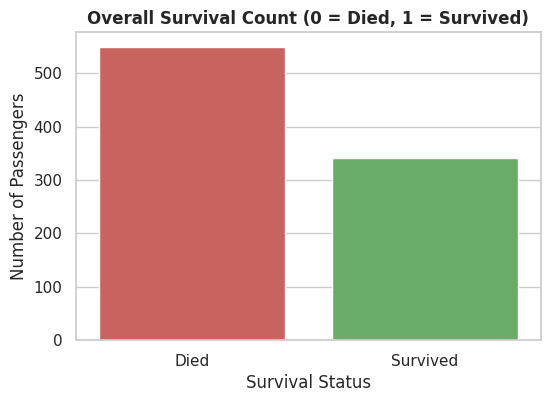

/tmp/ipykernel_2663/1178755495.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Sex', y='Survived', palette='pastel', errorbar=None)


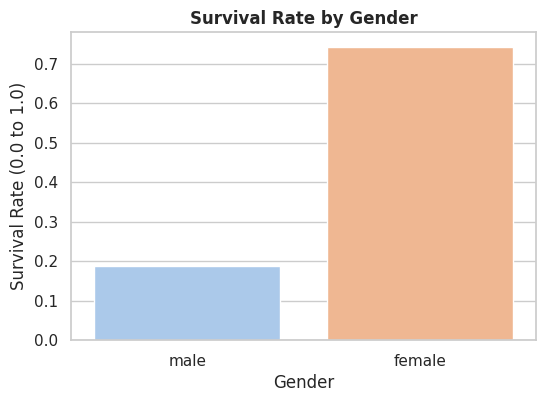

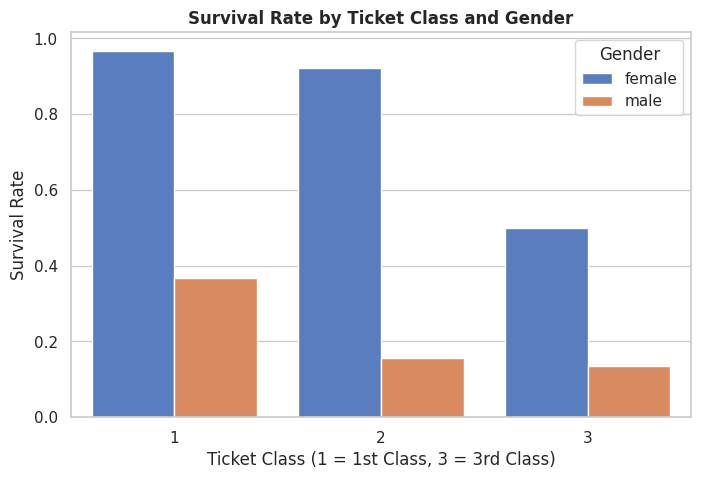

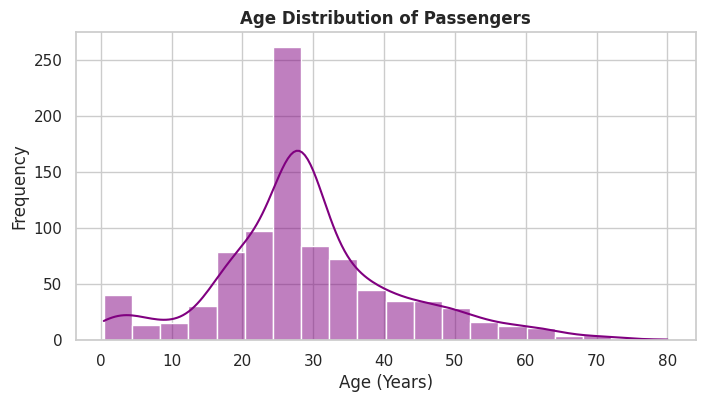

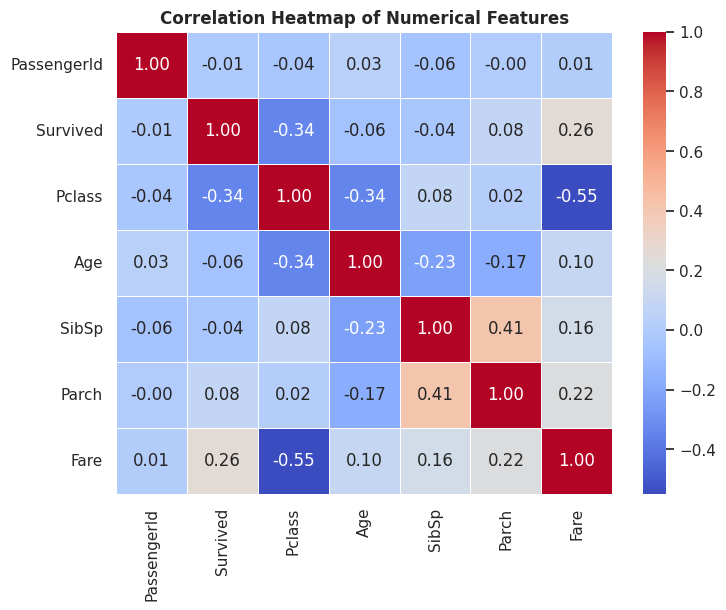

In [3]:
#visualiz

import matplotlib.pyplot as plt
import seaborn as sns

# Set a nice visual theme
sns.set_theme(style="whitegrid")

print("--- CREATING VISUALIZATIONS ---")

# ==========================================
# CHART 1: SURVIVAL COUNT (Bar Chart)
# Insight: Show the absolute number of people who survived vs died
# ==========================================
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Survived', palette=['#d9534f', '#5cb85c'])
plt.title('Overall Survival Count (0 = Died, 1 = Survived)', fontweight='bold')
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')
plt.xticks(ticks=[0, 1], labels=['Died', 'Survived'])
plt.show()


# ==========================================
# CHART 2: SURVIVAL BY GENDER (Bar Chart)
# Insight: Visualizing the "Women and Children First" rule
# ==========================================
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='Sex', y='Survived', palette='pastel', errorbar=None)
plt.title('Survival Rate by Gender', fontweight='bold')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (0.0 to 1.0)')
plt.show()


# ==========================================
# CHART 3: SURVIVAL BY CLASS & GENDER (Grouped Bar Chart)
# Insight: Visualizing how wealth (Class) and Gender combined affected survival
# ==========================================
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', palette='muted', errorbar=None)
plt.title('Survival Rate by Ticket Class and Gender', fontweight='bold')
plt.xlabel('Ticket Class (1 = 1st Class, 3 = 3rd Class)')
plt.ylabel('Survival Rate')
plt.legend(title='Gender')
plt.show()


# ==========================================
# CHART 4: AGE DISTRIBUTION (Histogram)
# Insight: Show the age spread of passengers and where the highest density is
# ==========================================
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Age', bins=20, kde=True, color='purple')
plt.title('Age Distribution of Passengers', fontweight='bold')
plt.xlabel('Age (Years)')
plt.ylabel('Frequency')
plt.show()


# ==========================================
# CHART 5: CORRELATION HEATMAP
# Insight: Show how different numerical variables relate to each other
# ==========================================
plt.figure(figsize=(8, 6))
# We only select numeric columns for correlation
numeric_df = df.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features', fontweight='bold')
plt.show()